# 2. Color tells a statistical story

**Question:** How can the same observations tell different visual stories?
**Objectives:** distinguish counts from rates, compare class breaks, use RColorBrewer,
and display missing values honestly. **Time:** 35 minutes. **Prerequisite:** Chapter 1.

Our 24 districts are fictional equal-area squares in local kilometres. Counts and populations
are simulated, complete observations for one imaginary period. A separate missing value is
introduced deliberately for display; it must never become zero.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=02-color-and-choropleths.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 02 | Original simulation and graphics.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: none | Outputs: maps, rate table.
# Dependencies: base R; optional RColorBrewer. Change log: initial lesson.
set.seed(20261116)
districts <- expand.grid(x = 0:5, y = 0:3)
districts$id <- sprintf("D%02d", seq_len(nrow(districts)))
districts$population <- sample(800:8000, nrow(districts))
districts$events <- rbinom(nrow(districts), districts$population,
                         prob = 0.03 + 0.006 * districts$x)
districts$rate <- 1000 * districts$events / districts$population
districts$display_rate <- districts$rate
districts$display_rate[7] <- NA_real_
stopifnot(all(districts$population > 0), all(districts$events <= districts$population))
print(districts[c("id", "population", "events", "display_rate")], row.names = FALSE)

  id population events display_rate
 D01       1865     64     34.31635
 D02       6922    256     36.98353
 D03       7215    301     41.71864
 D04       2550    126     49.41176
 D05       7306    386     52.83329
 D06       2491    138     55.39944
 D07       5407    172           NA
 D08       5206    176     33.80715
 D09       2985    125     41.87605
 D10       1941     89     45.85265
 D11       1825    110     60.27397
 D12       6611    387     58.53880
 D13       1238     19     15.34733
 D14       1820     73     40.10989
 D15       6525    272     41.68582
 D16       3959    189     47.73933
 D17       2316    137     59.15371
 D18       6151    413     67.14355
 D19       2136     68     31.83521
 D20       4790    174     36.32568
 D21       6224    296     47.55784
 D22       2486    106     42.63878
 D23       6247    338     54.10597
 D24       1811     98     54.11375


## Sequential palettes and classifications
Sequential colors represent ordered magnitudes. Diverging colors need a meaningful midpoint;
qualitative palettes identify categories. Numeric labels and a text table accompany the color.
The base palette below uses R's HCL implementation. The next cell replaces it with an attributed
ColorBrewer palette only if the package is installed.

In [2]:
palette5 <- hcl.colors(5, "Viridis")
palette_source <- "R HCL Viridis"

In [ ]:
if (requireNamespace("RColorBrewer", quietly = TRUE)) {
  palette5 <- RColorBrewer::brewer.pal(5, "YlGnBu")
  palette_source <- "ColorBrewer YlGnBu (Brewer; RColorBrewer by Neuwirth)"
  print(RColorBrewer::brewer.pal.info[c("YlGnBu", "RdBu", "Set2"), ])
} else {
  message("Optional RColorBrewer not installed. Using the labelled R HCL palette. To explore: webr::install('RColorBrewer').")
}

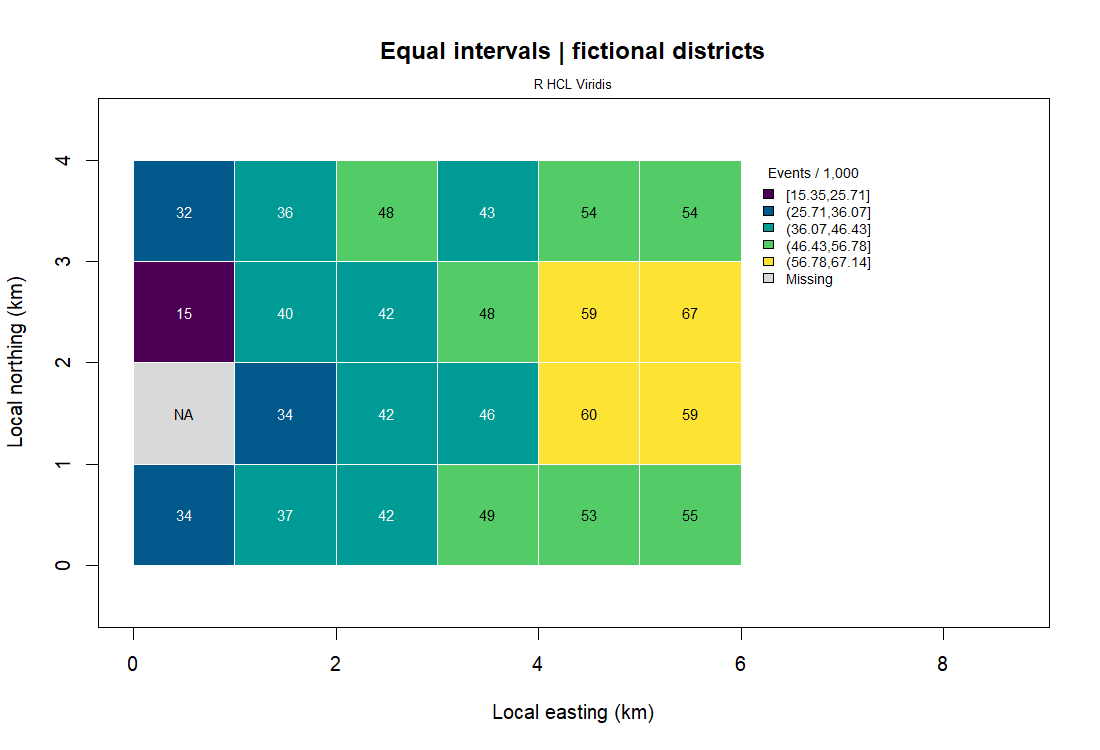

In [3]:
#' Draw classified synthetic square districts with numeric labels and an explicit NA class.
#' Inputs: values in district row order; strictly increasing breaks; title. Output: plot.
draw_districts <- function(values, breaks, title) {
  stopifnot(length(values) == nrow(districts), all(diff(breaks) > 0))
  groups <- cut(values, breaks, include.lowest = TRUE, dig.lab = 4)
  fill <- palette5[as.integer(groups)]
  fill[is.na(groups)] <- "grey85"
  # Adapt label contrast to the actual fill, including the optional Brewer palette.
  rgb <- col2rgb(fill) / 255
  brightness <- as.vector(c(.2126, .7152, .0722) %*% rgb)
  label_color <- ifelse(brightness < .5, "white", "black")
  plot(NA, xlim = c(0, 8.7), ylim = c(0, 4), asp = 1,
       xlab = "Local easting (km)", ylab = "Local northing (km)", main = title)
  rect(districts$x, districts$y, districts$x + 1, districts$y + 1, col = fill, border = "white")
  text(districts$x + .5, districts$y + .5,
       ifelse(is.na(values), "NA", round(values)), cex = .75, col = label_color)
  legend(6.1, 4, legend = c(levels(groups), "Missing"), fill = c(palette5, "grey85"),
         bty = "n", cex = .7, title = "Events / 1,000")
  mtext(palette_source, side = 3, line = .2, cex = .65)
}
equal_breaks <- seq(min(districts$rate), max(districts$rate), length.out = 6)
quantile_breaks <- unique(as.numeric(quantile(districts$rate, probs = seq(0, 1, .2))))
stopifnot(length(quantile_breaks) == 6) # If ties collapse classes, choose fewer classes explicitly.
draw_districts(districts$display_rate, equal_breaks, "Equal intervals | fictional districts")

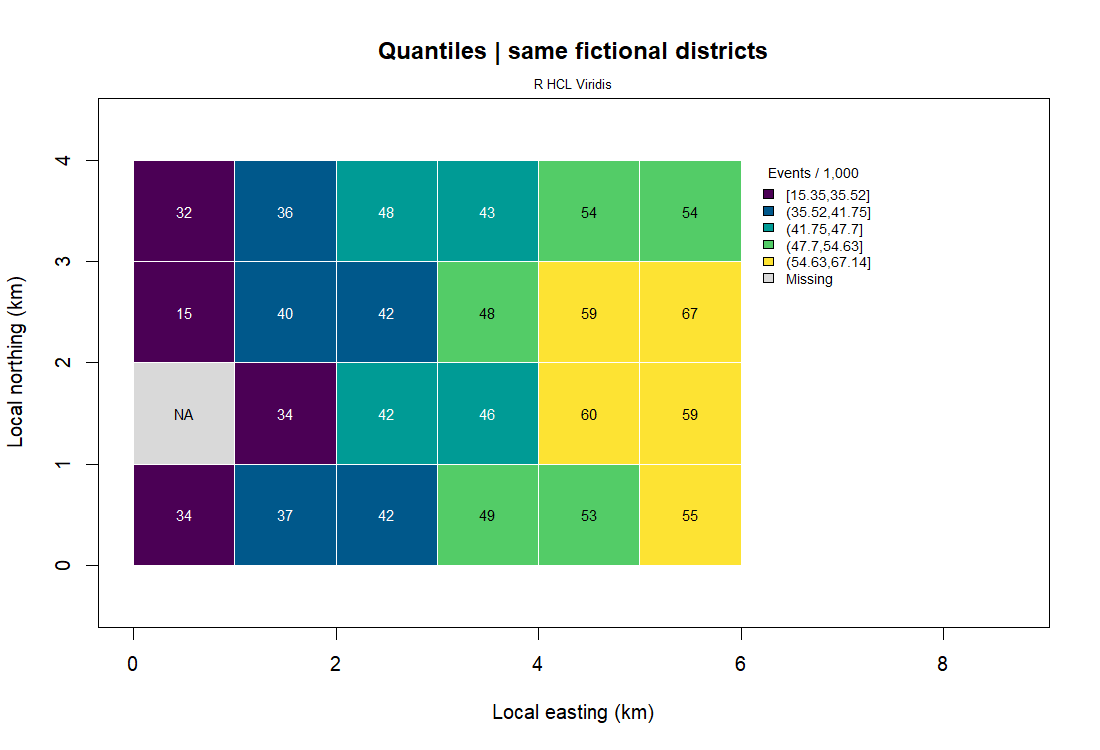

In [4]:
draw_districts(districts$display_rate, quantile_breaks, "Quantiles | same fictional districts")

**Interpretation:** quantiles balance the number of districts in each class; equal intervals
preserve equal numeric widths. Neither choice changes an event or denominator. Gray means
unavailable, not safe or zero. The original rate remains available for validation, not disclosure.
ColorBrewer's colorblind-friendly flag is useful design information, not an accessibility certification.

## Practice and check
1. Compare the district with the largest count to the district with the largest rate.
2. Introduce ties. Explain why `unique(quantile(...))` can yield fewer than six breakpoints.
3. Use a diverging palette for deviation from a stated reference rate, keeping the reference at the midpoint.
**Checkpoint:** counts depend on population; rates divide by population. Do not infer individual risk
from area averages (the ecological fallacy). Sparse denominators need uncertainty, explored later.

## Sources and attribution
[RColorBrewer, Erich Neuwirth](https://cran.r-project.org/package=RColorBrewer), Apache-2.0;
[ColorBrewer, Cynthia Brewer, Mark Harrower and collaborators](https://colorbrewer2.org/).
Palette values are obtained through the installed package, not copied into this repository.
See `citation("RColorBrewer")` for the installed version's citation.